# 标注集的 delta 与 relative delta 分布

数据为已完成评分的 **100,000 篇标注文档**，包含 label_train / label_dev / label_test。

对每篇文档，先按实际预测 token 数聚合平均 NLL，再计算：

$$\Delta L=L_{\mathrm{ref}}-L_{\mathrm{sft}},\qquad r=\frac{\Delta L}{\max(L_{\mathrm{ref}},10^{-6})}.$$

**正值表示数学 SFT 后该文档的 loss 降低；负值表示升高。** `relative delta` 对应项目里的 `relative_gain`；图表用 $100r$（百分比）显示，快照保留原始比例。

本 notebook 使用独立的本地快照，全部计算在 CPU 上进行。数据来源与 SHA-256 见 `manifest.json`。图像输出到 `figures/`。

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager, ticker
from IPython.display import display, Markdown

get_ipython().run_line_magic('matplotlib', 'inline')
BASE = Path.cwd()
manifest = json.loads((BASE/'manifest.json').read_text())
snapshot = BASE/manifest['snapshot']
assert hashlib.sha256(snapshot.read_bytes()).hexdigest() == manifest['snapshot_sha256']
df = pd.read_parquet(snapshot)
thresholds = json.loads((BASE/'snapshot/thresholds.json').read_text())
assert len(df) == 100000 and df.id.is_unique
assert np.isfinite(df[['delta_loss', 'relative_gain']].to_numpy()).all()
np.testing.assert_allclose(df.delta_loss, df.ref_loss-df.sft_loss, rtol=1e-12, atol=1e-12)
np.testing.assert_allclose(df.relative_gain, df.delta_loss/np.maximum(df.ref_loss,1e-6), rtol=1e-12, atol=1e-12)
df['relative_pct'] = 100*df.relative_gain

font_file = Path('/usr/share/fonts/truetype/droid/DroidSansFallbackFull.ttf')
if font_file.exists():
    font_manager.fontManager.addfont(str(font_file))
    cjk_name = font_manager.FontProperties(fname=str(font_file)).get_name()
    plt.rcParams['font.family'] = ['DejaVu Sans', cjk_name]
plt.rcParams.update({'font.size':11, 'axes.titlesize':13, 'axes.labelsize':11,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.unicode_minus':True, 'figure.dpi':110, 'savefig.dpi':180})
FIGURES = BASE/'figures'
FIGURES.mkdir(exist_ok=True)
specs = [
    {'key':'delta_loss', 'column':'delta_loss', 'title':'绝对下降量 delta',
     'xlabel':'Δ loss (nats / token)', 'color':'#3574BA', 'scale':1.0},
    {'key':'relative_gain', 'column':'relative_pct', 'title':'相对下降量 relative delta',
     'xlabel':'Relative delta (%)', 'color':'#BD7332', 'scale':100.0},
]
limits = {s['key']: np.quantile(df[s['column']].to_numpy(), [0.005,0.995]) for s in specs}

def reference_lines(ax, spec, median=False):
    ax.axvline(0, color='#237651', lw=1.4, label='0：loss 不变')
    cutoff = thresholds[spec['key']]['threshold']*spec['scale']
    ax.axvline(cutoff, color='#B74759', ls='--', lw=1.5, label='fastText 标签阈值（训练部分）')
    if median:
        ax.axvline(df[spec['column']].median(), color='#545E68', ls=':', lw=1.3, label='全量中位数')
    ax.set_xlabel(spec['xlabel'])
    if spec['scale'] == 100:
        ax.xaxis.set_major_formatter(ticker.PercentFormatter(xmax=100, decimals=1))

def finish(fig, name):
    fig.savefig(FIGURES/(name+'.png'), bbox_inches='tight')
    plt.show()
    plt.close(fig)

display(pd.Series(df.partition.value_counts(), name='文档数').to_frame())
print('快照 SHA-256:', manifest['snapshot_sha256'])
print('数据源完成时间:', manifest['source_completion']['completed_at_utc'])

,文档数
partition,
label_train,80909
label_test,9870
label_dev,9221


快照 SHA-256: 9f049f41ae9fc251a6037bfa69171a43080c2e2033a0c1fdd717a3892b0d6d41
数据源完成时间: 2026-11-02T22:00:05.818982+00:00


**1. 总体统计与分位数**

均值、标准差、分位数均按文档等权计算。相对下降量先逐篇计算后再取均值。下方额外列出按 Pythia token 数加权的正值占比，与分类器标注时的 token 预算口径对应。

In [2]:
summaries = []
for spec in specs:
    x = df[spec['column']].to_numpy()
    weight = df.pythia_tokens.to_numpy(dtype=np.float64)
    summaries.append({
        '指标': spec['title'],
        '单位': 'nats/token' if spec['scale']==1 else '%',
        '文档数':len(x), '均值':x.mean(), '中位数':np.median(x), '标准差':x.std(ddof=1),
        '最小值':x.min(), '最大值':x.max(),
        '正值篇数':int((x>0).sum()), '零值篇数':int((x==0).sum()), '负值篇数':int((x<0).sum()),
        '正值文档占比(%)':100*np.mean(x>0),
        '正值token占比(%)':100*weight[x>0].sum()/weight.sum(),
        'fastText标签阈值':thresholds[spec['key']]['threshold']*spec['scale'],
    })
summary = pd.DataFrame(summaries).set_index('指标')
summary.to_csv(BASE/'summary.csv')
display(summary.T)

quantiles = [0,0.001,0.005,0.01,0.05,0.25,0.5,0.75,0.95,0.99,0.995,0.999,1]
qtable = pd.DataFrame({
    '分位点':[f'{100*q:g}%' for q in quantiles],
    'delta (nats/token)':df.delta_loss.quantile(quantiles).to_numpy(),
    'relative delta (%)':df.relative_pct.quantile(quantiles).to_numpy(),
}).set_index('分位点')
qtable.to_csv(BASE/'quantiles.csv')
display(qtable.style.format('{:.6f}'))
print('分母保护触发数:', int((df.ref_loss<1e-6).sum()))
assert np.array_equal(np.sign(df.delta_loss), np.sign(df.relative_gain))

指标,绝对下降量 delta,相对下降量 relative delta
单位,nats/token,%
文档数,100000,100000
均值,-0.01144,-0.48609
中位数,-0.012107,-0.484888
标准差,0.026485,1.029057
最小值,-0.648636,-75.828944
最大值,0.9603,17.355785
正值篇数,13686,13686
零值篇数,1,1
负值篇数,86313,86313


,delta (nats/token),relative delta (%)
分位点,,
0%,-0.648636,-75.828944
0.1%,-0.181221,-7.063769
0.5%,-0.092963,-3.829952
1%,-0.071042,-2.891903
5%,-0.037273,-1.520284
25%,-0.019119,-0.764734
50%,-0.012107,-0.484888
75%,-0.005480,-0.224770
95%,0.014329,0.545377


分母保护触发数: 0


**2. 主体分布：中央 99% 区间**

横轴为各指标的 0.5%–99.5% 分位区间。纵轴是每个 bin 占**全量 100,000 篇**的百分比，未将可见部分重新归一化；图内注明窗口外的文档数。完整尾部见下一组图。

红虚线来自已经冻结的 fastText 训练标签阈值。阈值按 `label_train` 的 token 预算确定；这里展示的是三个划分的全量分布。

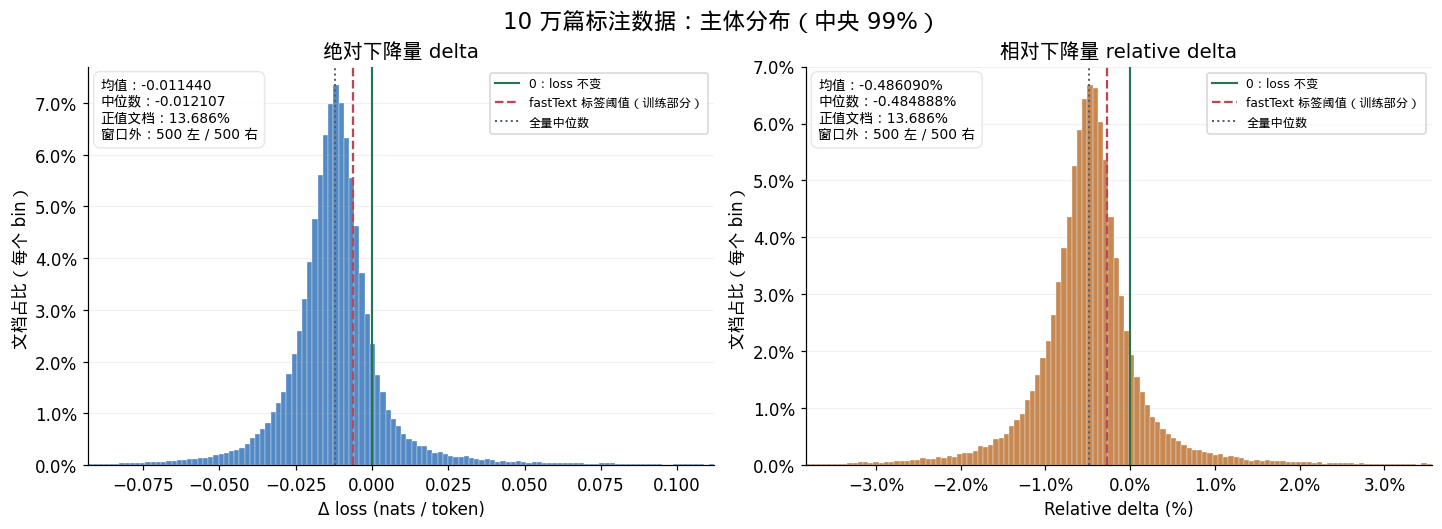

In [3]:
fig, axes = plt.subplots(1,2, figsize=(13,4.7), layout='constrained')
for ax, spec in zip(axes, specs):
    x = df[spec['column']].to_numpy()
    low, high = limits[spec['key']]
    ax.hist(x, bins=np.linspace(low,high,121), weights=np.full(len(x),100/len(x)),
            color=spec['color'], alpha=0.85, edgecolor='white', linewidth=0.25)
    ax.set_xlim(low,high)
    reference_lines(ax,spec,median=True)
    ax.set_title(spec['title'])
    ax.set_ylabel('文档占比（每个 bin）')
    ax.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=100))
    ax.grid(axis='y',alpha=.18)
    ax.text(.02,.97,
            f'均值：{x.mean():.6f}'+ ('%' if spec['scale']==100 else '')+
            f'\n中位数：{np.median(x):.6f}'+ ('%' if spec['scale']==100 else '')+
            f'\n正值文档：{100*np.mean(x>0):.3f}%'+
            f'\n窗口外：{int((x<low).sum()):,} 左 / {int((x>high).sum()):,} 右',
            transform=ax.transAxes, va='top', fontsize=9,
            bbox={'facecolor':'white','edgecolor':'#E2E6EB','alpha':.9,'boxstyle':'round,pad=.5'})
    ax.legend(loc='upper right',fontsize=8)
fig.suptitle('10 万篇标注数据：主体分布（中央 99%）',fontsize=15)
finish(fig,'01_central_distributions')

**3. 全范围分布：包括所有极端值**

横轴覆盖最小值到最大值，纵轴使用对数文档数。这里不删除、不截断或 winsorize 分数；空 bin 不显示正柱高。

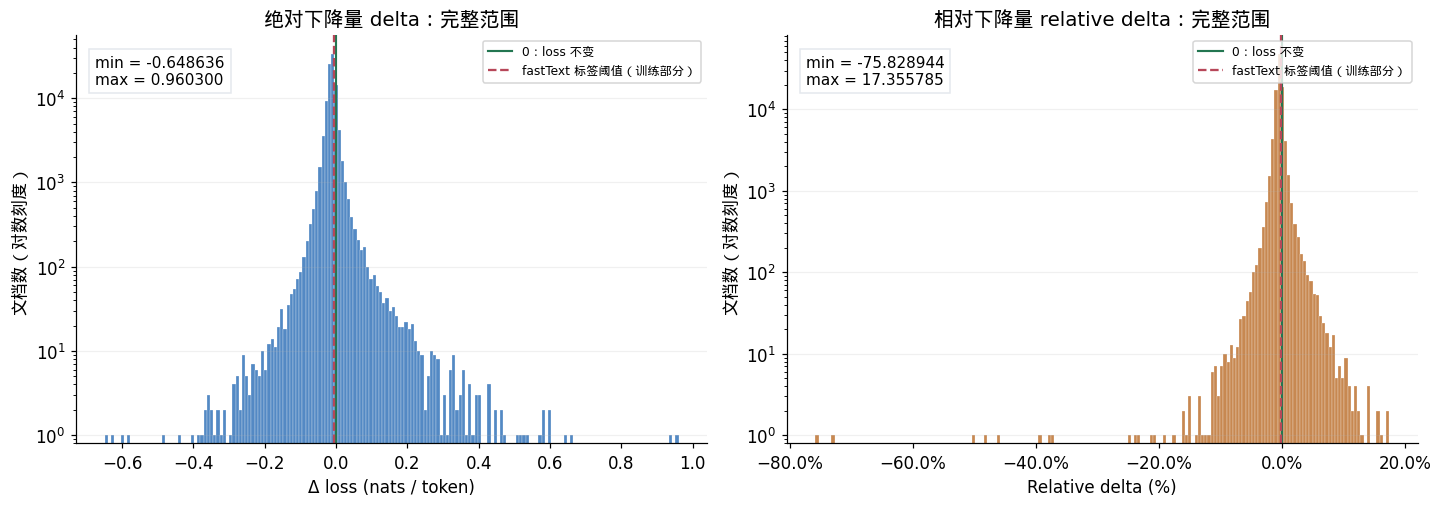

In [4]:
fig, axes = plt.subplots(1,2, figsize=(13,4.5), layout='constrained')
for ax, spec in zip(axes,specs):
    x = df[spec['column']].to_numpy()
    ax.hist(x,bins=180,color=spec['color'],alpha=.85,log=True,edgecolor='white',linewidth=.2)
    reference_lines(ax,spec)
    ax.set_title(spec['title']+'：完整范围')
    ax.set_ylabel('文档数（对数刻度）')
    ax.set_ylim(bottom=.8)
    ax.grid(axis='y',alpha=.18)
    ax.text(.03,.95,f'min = {x.min():.6f}\nmax = {x.max():.6f}',
            transform=ax.transAxes,va='top',fontsize=10,
            bbox={'facecolor':'white','edgecolor':'#E2E6EB','alpha':.9})
    ax.legend(loc='upper right',fontsize=8)
finish(fig,'02_full_range_log_histograms')

**4. 累积分布：文档权重与 token 权重**

实线表示低于或等于横轴分数的文档占比；虚线表示同一条件下的 Pythia token 占比。CDF 使用全量数据计算，仅将横轴放大到中央 99% 区间。

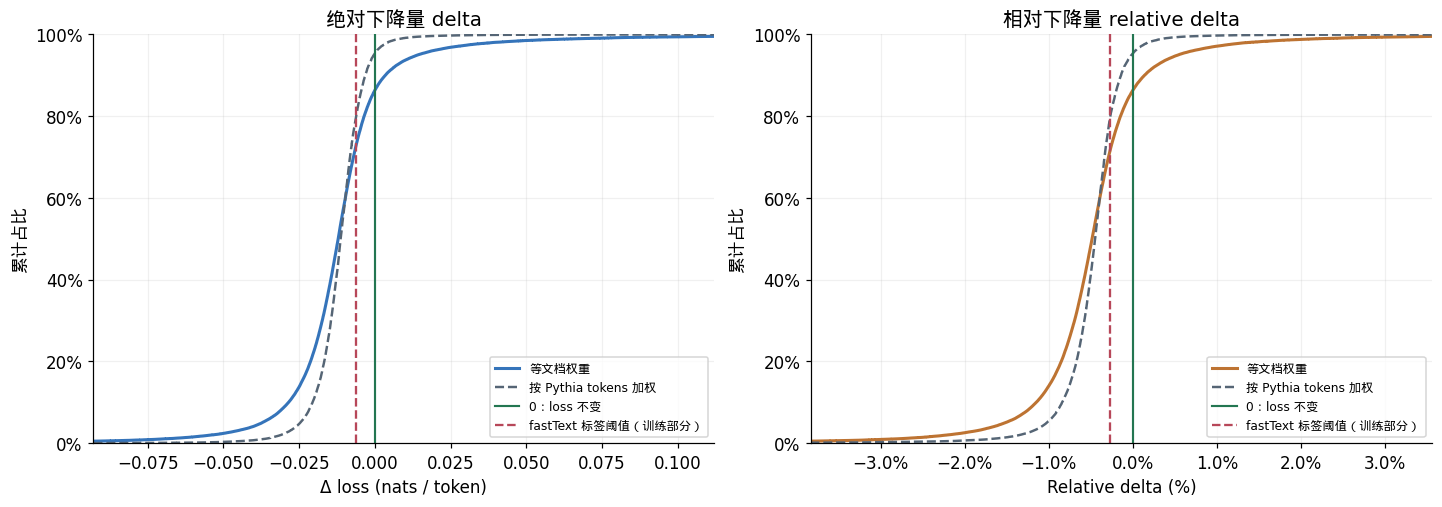

In [5]:
fig, axes = plt.subplots(1,2, figsize=(13,4.5), layout='constrained')
for ax,spec in zip(axes,specs):
    x = df[spec['column']].to_numpy()
    order = np.argsort(x,kind='stable')
    weight = df.pythia_tokens.to_numpy(dtype=np.float64)[order]
    ax.plot(x[order],100*np.arange(1,len(x)+1)/len(x),
            color=spec['color'],lw=2,label='等文档权重',drawstyle='steps-post')
    ax.plot(x[order],100*np.cumsum(weight)/weight.sum(),
            color='#556575',lw=1.6,ls='--',label='按 Pythia tokens 加权',drawstyle='steps-post')
    reference_lines(ax,spec)
    ax.set_xlim(*limits[spec['key']]); ax.set_ylim(0,100)
    ax.set_title(spec['title'])
    ax.set_ylabel('累计占比')
    ax.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=100))
    ax.grid(alpha=.18)
    ax.legend(loc='lower right',fontsize=8)
finish(fig,'03_document_token_ecdf')

**5. train / dev / test 的分布对照**

三个划分使用相同的横轴区间和 bin 边界，各自按该划分的文档数归一化；分母包含各自窗口外的尾部样本。此图用于查看按域名划分后，分布是否发生变化。

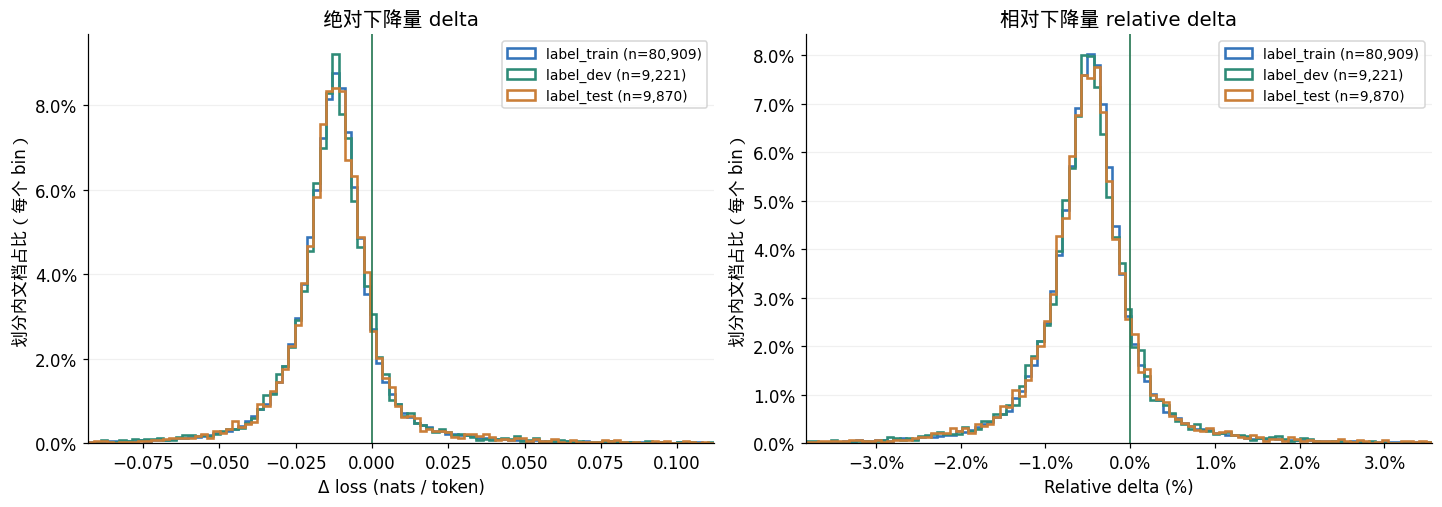

,split,metric,display_unit,documents,mean,median,positive_document_percent
0,label_train,delta_loss,nats/token,80909,-0.011439,-0.012110,13.593049
1,label_dev,delta_loss,nats/token,9221,-0.011792,-0.012167,14.076564
2,label_test,delta_loss,nats/token,9870,-0.011126,-0.012035,14.083080
3,label_train,relative_gain,%,80909,-0.484900,-0.483392,13.593049
4,label_dev,relative_gain,%,9221,-0.497004,-0.494945,14.076564
5,label_test,relative_gain,%,9870,-0.485647,-0.487735,14.083080


In [6]:
split_colors={'label_train':'#3574BA','label_dev':'#2E8B77','label_test':'#CA7E38'}
split_rows=[]
fig, axes = plt.subplots(1,2,figsize=(13,4.5),layout='constrained')
for ax,spec in zip(axes,specs):
    edges=np.linspace(*limits[spec['key']],101)
    for split in ['label_train','label_dev','label_test']:
        group=df[df.partition==split]
        x=group[spec['column']].to_numpy()
        ax.hist(x,bins=edges,weights=np.full(len(x),100/len(x)),histtype='step',lw=1.7,
                color=split_colors[split],label=f'{split} (n={len(x):,})')
        split_rows.append({'split':split,'metric':spec['key'],'display_unit':'%' if spec['scale']==100 else 'nats/token',
                           'documents':len(x),'mean':float(x.mean()),'median':float(np.median(x)),
                           'positive_document_percent':float(100*np.mean(x>0))})
    ax.axvline(0,color='#237651',lw=1.1)
    ax.set_xlim(*limits[spec['key']]);ax.set_title(spec['title']);ax.set_xlabel(spec['xlabel'])
    ax.set_ylabel('划分内文档占比（每个 bin）')
    ax.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=100))
    if spec['scale']==100:ax.xaxis.set_major_formatter(ticker.PercentFormatter(xmax=100,decimals=1))
    ax.grid(axis='y',alpha=.18);ax.legend(fontsize=9)
finish(fig,'04_split_distributions')
split_summary=pd.DataFrame(split_rows)
split_summary.to_csv(BASE/'split_summary.csv',index=False)
display(split_summary)

**6. 两种分数的联合分布**

散点以 hexbin 聚合，颜色表示文档数（对数刻度）。显示窗口为两种指标各自中央 99% 区间的交集；图中明确列出可见样本数。Pearson 与 Spearman 相关系数均使用全部 100,000 篇计算。

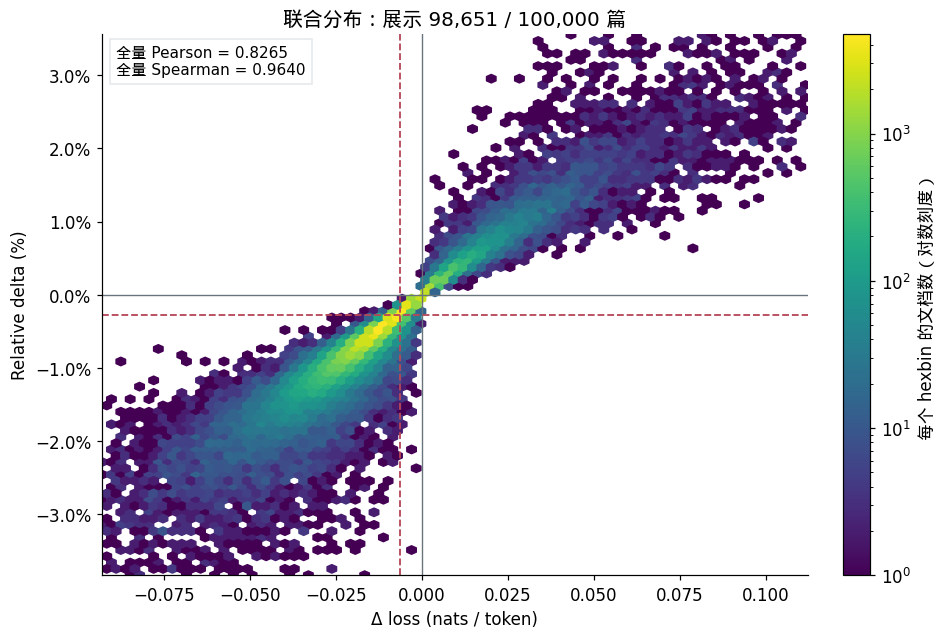

全量数据中，**13.686%** 的文档 loss 降低，**86,313 篇**升高，**1 篇**恰为零。绝对下降量均值为 **-0.011440 nats/token**；相对下降量均值为 **-0.4861%**。

In [7]:
x=df.delta_loss.to_numpy();y=df.relative_pct.to_numpy()
lo_x,hi_x=limits['delta_loss'];lo_y,hi_y=limits['relative_gain']
inside=(x>=lo_x)&(x<=hi_x)&(y>=lo_y)&(y<=hi_y)
pearson=float(df.delta_loss.corr(df.relative_gain,method='pearson'))
spearman=float(df.delta_loss.corr(df.relative_gain,method='spearman'))
fig,ax=plt.subplots(figsize=(8.5,5.7),layout='constrained')
hexes=ax.hexbin(x[inside],y[inside],gridsize=75,bins='log',mincnt=1,cmap='viridis')
ax.axvline(0,color='#67747B',lw=.9);ax.axhline(0,color='#67747B',lw=.9)
ax.axvline(thresholds['delta_loss']['threshold'],color='#B74759',ls='--',lw=1.2)
ax.axhline(100*thresholds['relative_gain']['threshold'],color='#B74759',ls='--',lw=1.2)
ax.set_xlim(lo_x,hi_x);ax.set_ylim(lo_y,hi_y)
ax.set_xlabel('Δ loss (nats / token)');ax.set_ylabel('Relative delta (%)')
ax.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=100,decimals=1))
ax.set_title(f'联合分布：展示 {int(inside.sum()):,} / {len(df):,} 篇')
fig.colorbar(hexes,ax=ax,label='每个 hexbin 的文档数（对数刻度）')
ax.text(.02,.98,f'全量 Pearson = {pearson:.4f}\n全量 Spearman = {spearman:.4f}',
        transform=ax.transAxes,va='top',fontsize=10,
        bbox={'facecolor':'white','edgecolor':'#E2E6EB','alpha':.94})
finish(fig,'05_joint_distribution')

diagnostics={
    'documents':len(df),
    'positive_documents':int((df.delta_loss>0).sum()),
    'negative_documents':int((df.delta_loss<0).sum()),
    'zero_documents':int((df.delta_loss==0).sum()),
    'positive_document_fraction':float((df.delta_loss>0).mean()),
    'mean_delta_loss':float(df.delta_loss.mean()),
    'median_delta_loss':float(df.delta_loss.median()),
    'mean_relative_gain':float(df.relative_gain.mean()),
    'median_relative_gain':float(df.relative_gain.median()),
    'pearson':pearson,'spearman':spearman,
    'central_joint_documents':int(inside.sum()),
    'relative_display_multiplier':100,
    'source_sha256':manifest['source_scores_sha256'],
}
(BASE/'distribution_summary.json').write_text(json.dumps(diagnostics,ensure_ascii=False,indent=2)+'\n')
display(Markdown(
    f'全量数据中，**{100*diagnostics["positive_document_fraction"]:.3f}%** 的文档 loss 降低，'
    f'**{diagnostics["negative_documents"]:,} 篇**升高，**{diagnostics["zero_documents"]} 篇**恰为零。'
    f'绝对下降量均值为 **{diagnostics["mean_delta_loss"]:.6f} nats/token**；'
    f'相对下降量均值为 **{100*diagnostics["mean_relative_gain"]:.4f}%**。'))

两项 fastText 标签阈值均小于零。因此 include 集合包含一部分 loss 上升较小的文档；标签表达的是固定预算下的高分排名。该 notebook 展示 teacher 的分数分布，后续预训练收益请结合主实验报告评估。

图像、统计表和绘图所需快照均保存在此目录，可以独立复查；原始评分、分类器和训练状态未被修改。